In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import warnings
warnings.filterwarnings("ignore")

dane = pd.read_csv('warszawa_okecie_temp_dobowa.csv')
dane['data'] = pd.to_datetime(dane['data'])
dane.set_index('data', inplace=True)


suma_brakow = dane['temp_srednia'].isnull().sum()
print(suma_brakow)

0


In [27]:
y = dane['temp_srednia']
h = 365*3

train = y.iloc[:-h]
test = y.iloc[-h:]

model = ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=365).fit(
    smoothing_seasonal=0.001, smoothing_trend=0.001, smoothing_level=0.3
)

dane['fittedvalues'] = model.fittedvalues
forecast = model.forecast(h*10)

for nazwa in ['smoothing_level', 'smoothing_trend', 'smoothing_seasonal']:
    print(nazwa, round(model.params[nazwa], 4))

smoothing_level 0.3
smoothing_trend 0.001
smoothing_seasonal 0.001


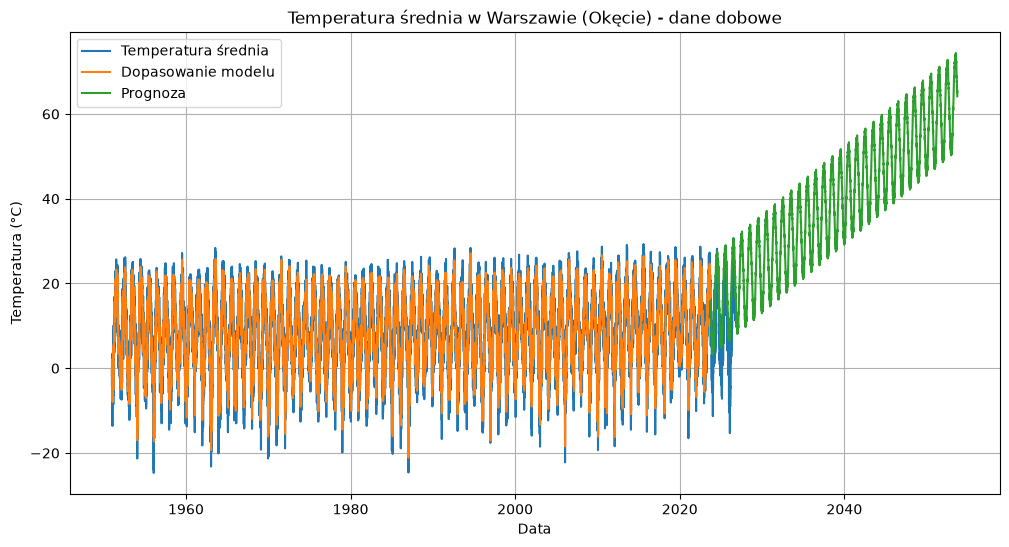

In [28]:
figure = plt.figure(figsize=(12, 6))
plt.plot(dane['temp_srednia'], label='Temperatura średnia')
plt.plot(dane['fittedvalues'], label='Dopasowanie modelu')
plt.plot(forecast, label='Prognoza')
plt.title('Temperatura średnia w Warszawie (Okęcie) - dane dobowe')
plt.xlabel('Data')
plt.ylabel('Temperatura (°C)')
plt.legend()
plt.grid()
plt.show()